# Day 054 | ML Pipeline with Scikit-Learn

## 100 Days of ML for Geotechnical Engineering
**Phase:** Classical Machine Learning

**Author:** Ripon Chandra Malo  
**Date:** YYYY-MM-DD  

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| sklearn Pipeline | Chain preprocessing + model in one object | One-click from raw data to prediction |
| ColumnTransformer | Apply different transforms to different columns | Scale numbers, encode soil types separately |
| SimpleImputer | Fill missing values automatically | Handle missing lab test results |
| StandardScaler | Normalize features to zero mean, unit variance | Put depth (m) and cohesion (kPa) on same scale |
| OneHotEncoder | Convert categories to binary columns | Soil type (Clay/Sand/Silt) to numeric |
| joblib save/load | Persist trained pipelines to disk | Deploy model for future predictions |

---

## Our Geotechnical Problem

We build a **complete, production-ready ML pipeline** for predicting soil settlement.  
Raw geotechnical data has:
- **Missing values** (incomplete lab tests)
- **Mixed types** (numeric measurements + categorical soil types)
- **Different scales** (depth in meters vs unit weight in kN/m3)

A proper pipeline handles ALL of this automatically and prevents data leakage.

---

## Part 1: Generate Realistic Geotechnical Data with Missing Values

In [1]:
# ─────────────────────────────────────────────────────
# IMPORTS AND DATA GENERATION
# ─────────────────────────────────────────────────────

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
n = 400

# Generate complete data
soil_type = np.random.choice(['Clay', 'Sand', 'Silt', 'Gravel'], n, p=[0.35, 0.30, 0.25, 0.10])
depth = np.random.uniform(1, 20, n)
unit_weight = np.where(soil_type == 'Clay', np.random.uniform(16, 19, n),
              np.where(soil_type == 'Sand', np.random.uniform(17, 21, n),
              np.where(soil_type == 'Silt', np.random.uniform(16, 19, n),
                       np.random.uniform(18, 22, n))))
void_ratio = np.where(soil_type == 'Clay', np.random.uniform(0.6, 1.2, n),
             np.where(soil_type == 'Sand', np.random.uniform(0.4, 0.8, n),
                      np.random.uniform(0.5, 1.0, n)))
liquid_limit = np.where(soil_type == 'Clay', np.random.uniform(35, 70, n),
              np.where(soil_type == 'Silt', np.random.uniform(25, 50, n),
                       np.random.uniform(0, 25, n)))
N_value = np.random.randint(3, 50, n)
applied_pressure = np.random.uniform(50, 300, n)  # kPa

# Settlement (target)
settlement = (0.3 * void_ratio * applied_pressure / (1 + void_ratio) *
              depth / 100 * (1 + 0.01 * liquid_limit) +
              np.random.normal(0, 2, n))
settlement = np.clip(settlement, 1, 80)  # mm

df = pd.DataFrame({
    'soil_type': soil_type,
    'depth_m': depth,
    'unit_weight': unit_weight,
    'void_ratio': void_ratio,
    'liquid_limit': liquid_limit,
    'N_value': N_value.astype(float),
    'applied_pressure_kPa': applied_pressure,
    'settlement_mm': settlement
})

# Introduce realistic missing values
np.random.seed(99)
for col, pct in [('void_ratio', 0.10), ('liquid_limit', 0.15),
                 ('N_value', 0.08), ('unit_weight', 0.05)]:
    mask = np.random.rand(n) < pct
    df.loc[mask, col] = np.nan

print(f"Dataset shape: {df.shape}")
print(f"\nMissing values:")
print(df.isnull().sum())
print(f"\nSample data:")
print(df.head(8).to_string())

Dataset shape: (400, 8)

Missing values:
soil_type                0
depth_m                  0
unit_weight             21
void_ratio              36
liquid_limit            53
N_value                 29
applied_pressure_kPa     0
settlement_mm            0
dtype: int64

Sample data:
  soil_type    depth_m  unit_weight  void_ratio  liquid_limit  N_value  applied_pressure_kPa  settlement_mm
0      Sand   2.959354    20.033053    0.717038      3.082094     21.0             59.178236       3.292032
1    Gravel  18.148505    18.987915    0.751566     12.964042     46.0            168.692252       4.517241
2      Silt  10.599795    16.679969    0.596932     44.004023     36.0            134.080849       2.498453
3      Sand  16.702692    18.294441         NaN      8.953493     37.0            280.133971       6.932599
4      Clay   7.080942    17.272392    1.006272     42.654843      3.0             53.000757       3.594827
5      Clay  18.014941    18.209333    0.963468     41.399322     23

---

## Part 2: The WRONG Way — Manual Steps (Data Leakage Risk)

In [2]:
# ─────────────────────────────────────────────────────
# THE WRONG WAY — Common data leakage mistakes
# ─────────────────────────────────────────────────────

print("COMMON MISTAKES (DO NOT DO THIS):")
print("=" * 50)
print()
print("1. Imputing BEFORE train/test split:")
print("   df['void_ratio'].fillna(df['void_ratio'].mean())  # WRONG!")
print("   The mean includes test data information = data leakage")
print()
print("2. Scaling BEFORE train/test split:")
print("   scaler.fit_transform(X)  # WRONG! Test data influences scaling")
print()
print("3. Encoding BEFORE train/test split:")
print("   pd.get_dummies(df)  # WRONG! Test categories leak into train")
print()
print("SOLUTION: Use sklearn Pipeline to prevent all of these!")
print("Pipeline ensures fit() is called ONLY on training data.")

COMMON MISTAKES (DO NOT DO THIS):

1. Imputing BEFORE train/test split:
   df['void_ratio'].fillna(df['void_ratio'].mean())  # WRONG!
   The mean includes test data information = data leakage

2. Scaling BEFORE train/test split:
   scaler.fit_transform(X)  # WRONG! Test data influences scaling

3. Encoding BEFORE train/test split:
   pd.get_dummies(df)  # WRONG! Test categories leak into train

SOLUTION: Use sklearn Pipeline to prevent all of these!
Pipeline ensures fit() is called ONLY on training data.


---

## Part 3: ColumnTransformer — Different Transforms for Different Columns

In [3]:
# ─────────────────────────────────────────────────────
# COLUMN TRANSFORMER — Handle numeric and categorical separately
# ─────────────────────────────────────────────────────

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify column types
numeric_features = ['depth_m', 'unit_weight', 'void_ratio',
                    'liquid_limit', 'N_value', 'applied_pressure_kPa']
categorical_features = ['soil_type']

# Numeric pipeline: impute median -> scale
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: impute mode -> one-hot encode
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# Combine with ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

print("Preprocessing Pipeline Structure:")
print("  Numeric:     Impute (median) -> StandardScaler")
print("  Categorical: Impute (mode)   -> OneHotEncoder")
print(f"\nNumeric features ({len(numeric_features)}):     {numeric_features}")
print(f"Categorical features ({len(categorical_features)}): {categorical_features}")

Preprocessing Pipeline Structure:
  Numeric:     Impute (median) -> StandardScaler
  Categorical: Impute (mode)   -> OneHotEncoder

Numeric features (6):     ['depth_m', 'unit_weight', 'void_ratio', 'liquid_limit', 'N_value', 'applied_pressure_kPa']
Categorical features (1): ['soil_type']


---

## Part 4: Full Pipeline — Preprocessing + Model

In [4]:
# ─────────────────────────────────────────────────────
# FULL PIPELINE — Preprocess + Train in one object
# ─────────────────────────────────────────────────────

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = df.drop('settlement_mm', axis=1)
y = df['settlement_mm']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create full pipeline
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42))
])

# Fit the entire pipeline on training data
full_pipeline.fit(X_train, y_train)

# Predict on test data (preprocessing happens automatically!)
y_pred = full_pipeline.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)

print("Full Pipeline Results:")
print(f"  R2   = {r2:.4f}")
print(f"  RMSE = {rmse:.2f} mm")
print(f"  MAE  = {mae:.2f} mm")
print()
print("Key advantage: ONE call to fit(), ONE call to predict()")
print("No data leakage, no manual steps, no forgetting transforms.")

Full Pipeline Results:
  R2   = 0.6262
  RMSE = 1.72 mm
  MAE  = 1.37 mm

Key advantage: ONE call to fit(), ONE call to predict()
No data leakage, no manual steps, no forgetting transforms.


In [5]:
# ─────────────────────────────────────────────────────
# VISUALIZE PIPELINE STEPS
# ─────────────────────────────────────────────────────

from sklearn import set_config
set_config(display='diagram')

print("Pipeline visualization:")
full_pipeline

Pipeline visualization:


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

---

## Part 5: Cross-Validation with Pipelines

In [6]:
# ─────────────────────────────────────────────────────
# CROSS-VALIDATION — Pipeline prevents leakage in each fold
# ─────────────────────────────────────────────────────

from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(full_pipeline, X_train, y_train,
                            cv=5, scoring='r2')

print("5-Fold Cross-Validation (on training data):")
print(f"  R2 scores: {cv_scores.round(4)}")
print(f"  Mean R2:   {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
print()
print("In each fold, the pipeline re-fits preprocessing on fold's train split.")
print("This prevents data leakage between folds!")

5-Fold Cross-Validation (on training data):
  R2 scores: [0.5495 0.5801 0.4844 0.5849 0.5521]
  Mean R2:   0.5502 +/- 0.0359

In each fold, the pipeline re-fits preprocessing on fold's train split.
This prevents data leakage between folds!


---

## Part 6: Comparing Multiple Models via Pipelines

Model Comparison (all using same Pipeline preprocessing):
                   CV Mean R2  CV Std  Test R2
Ridge                  0.5350  0.0409   0.5216
Lasso                  0.5364  0.0205   0.5113
SVR                    0.4306  0.1043   0.6021
Random Forest          0.5502  0.0359   0.6262
Gradient Boosting      0.5167  0.0461   0.6150


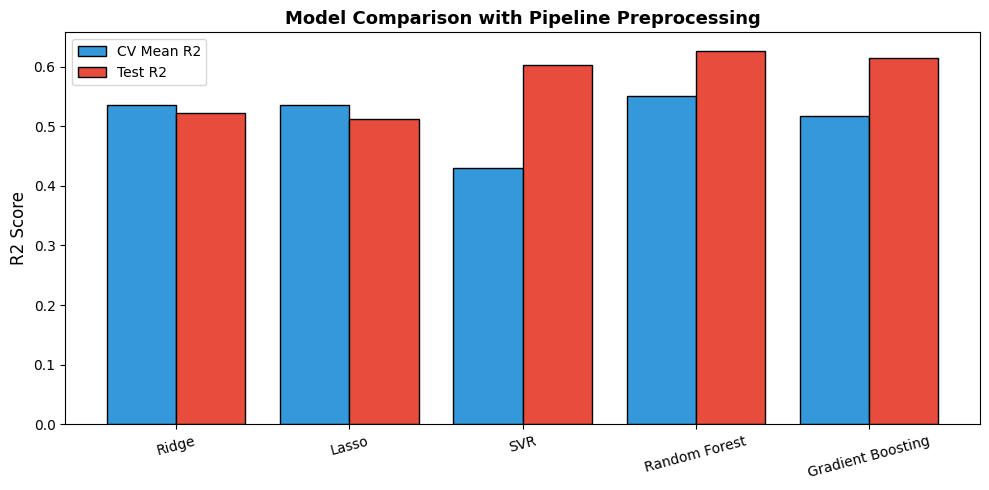

In [7]:
# ─────────────────────────────────────────────────────
# COMPARE MODELS — Same preprocessing, different models
# ─────────────────────────────────────────────────────

from sklearn.linear_model import Ridge, Lasso
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

models = {
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.1),
    'SVR': SVR(kernel='rbf', C=10),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, max_depth=5, random_state=42)
}

results = {}
for name, model in models.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    cv = cross_val_score(pipe, X_train, y_train, cv=5, scoring='r2')
    pipe.fit(X_train, y_train)
    test_r2 = r2_score(y_test, pipe.predict(X_test))
    results[name] = {
        'CV Mean R2': cv.mean(),
        'CV Std': cv.std(),
        'Test R2': test_r2
    }

results_df = pd.DataFrame(results).T.round(4)
print("Model Comparison (all using same Pipeline preprocessing):")
print("=" * 60)
print(results_df)

fig, ax = plt.subplots(figsize=(10, 5))
x = range(len(results))
ax.bar(x, results_df['CV Mean R2'], width=0.4, label='CV Mean R2',
       color='#3498db', edgecolor='black')
ax.bar([i+0.4 for i in x], results_df['Test R2'], width=0.4, label='Test R2',
       color='#e74c3c', edgecolor='black')
ax.set_xticks([i+0.2 for i in x])
ax.set_xticklabels(results_df.index, rotation=15)
ax.set_ylabel('R2 Score', fontsize=12)
ax.set_title('Model Comparison with Pipeline Preprocessing', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---

## Part 7: Save and Load Pipeline with joblib

In [8]:
# ─────────────────────────────────────────────────────
# SAVE PIPELINE — Persist to disk for deployment
# ─────────────────────────────────────────────────────

import joblib
import os

# Save the best pipeline
best_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(n_estimators=200, max_depth=5, random_state=42))
])
best_pipeline.fit(X_train, y_train)

# Save to disk
model_path = 'settlement_pipeline.joblib'
joblib.dump(best_pipeline, model_path)
file_size = os.path.getsize(model_path) / 1024

print(f"Pipeline saved to: {model_path}")
print(f"File size: {file_size:.1f} KB")
print()

# Load and verify
loaded_pipeline = joblib.load(model_path)
y_pred_loaded = loaded_pipeline.predict(X_test)
r2_loaded = r2_score(y_test, y_pred_loaded)

print(f"Loaded pipeline R2: {r2_loaded:.4f}")
print(f"Predictions match:  {np.allclose(best_pipeline.predict(X_test), y_pred_loaded)}")
print()
print("The saved pipeline includes ALL preprocessing steps.")
print("Just call loaded_pipeline.predict(new_raw_data) on new data!")

Pipeline saved to: settlement_pipeline.joblib
File size: 904.5 KB

Loaded pipeline R2: 0.6150
Predictions match:  True

The saved pipeline includes ALL preprocessing steps.
Just call loaded_pipeline.predict(new_raw_data) on new data!


In [9]:
# ─────────────────────────────────────────────────────
# USE LOADED PIPELINE ON NEW DATA
# ─────────────────────────────────────────────────────

# Simulate new field data arriving
new_data = pd.DataFrame({
    'soil_type': ['Clay', 'Sand', 'Silt'],
    'depth_m': [5.0, 10.0, 3.0],
    'unit_weight': [17.5, 19.0, np.nan],  # missing value!
    'void_ratio': [0.9, 0.6, 0.75],
    'liquid_limit': [45, np.nan, 30],      # missing value!
    'N_value': [12, 25, 8],
    'applied_pressure_kPa': [100, 200, 150]
})

print("New field data (with missing values):")
print(new_data.to_string())
print()

# Predict with loaded pipeline — handles missing values automatically!
predictions = loaded_pipeline.predict(new_data)
print("Predicted settlements:")
for i, (st, pred) in enumerate(zip(new_data['soil_type'], predictions)):
    print(f"  Site {i+1} ({st}): {pred:.1f} mm")
print()
print("The pipeline automatically imputed missing values and scaled features!")

New field data (with missing values):
  soil_type  depth_m  unit_weight  void_ratio  liquid_limit  N_value  applied_pressure_kPa
0      Clay      5.0         17.5        0.90          45.0       12                   100
1      Sand     10.0         19.0        0.60           NaN       25                   200
2      Silt      3.0          NaN        0.75          30.0        8                   150

Predicted settlements:
  Site 1 (Clay): 2.0 mm
  Site 2 (Sand): 2.7 mm
  Site 3 (Silt): 1.8 mm

The pipeline automatically imputed missing values and scaled features!


---

## Part 8: Inspect Pipeline Internals

In [10]:
# ─────────────────────────────────────────────────────
# INSPECT PIPELINE — What did it learn?
# ─────────────────────────────────────────────────────

# Access preprocessor from pipeline
fitted_preprocessor = best_pipeline.named_steps['preprocessor']

# Get numeric imputer values
num_imputer = fitted_preprocessor.named_transformers_['num'].named_steps['imputer']
print("Imputer learned medians (from training data only):")
for feat, med in zip(numeric_features, num_imputer.statistics_):
    print(f"  {feat:25s}: {med:.2f}")

# Get scaler parameters
num_scaler = fitted_preprocessor.named_transformers_['num'].named_steps['scaler']
print("\nScaler learned means and stds:")
for feat, m, s in zip(numeric_features, num_scaler.mean_, num_scaler.scale_):
    print(f"  {feat:25s}: mean={m:.2f}, std={s:.2f}")

# Get encoder categories
cat_encoder = fitted_preprocessor.named_transformers_['cat'].named_steps['encoder']
print(f"\nEncoder categories: {cat_encoder.categories_[0].tolist()}")
print(f"Encoded columns (drop='first'): {cat_encoder.get_feature_names_out(['soil_type']).tolist()}")

# Total features after transformation
X_transformed = fitted_preprocessor.transform(X_test)
print(f"\nOriginal features: {X_test.shape[1]}")
print(f"Transformed features: {X_transformed.shape[1]}")

Imputer learned medians (from training data only):
  depth_m                  : 10.51
  unit_weight              : 18.14
  void_ratio               : 0.75
  liquid_limit             : 36.65
  N_value                  : 23.00
  applied_pressure_kPa     : 169.69

Scaler learned means and stds:
  depth_m                  : mean=10.45, std=5.48
  unit_weight              : mean=18.14, std=1.24
  void_ratio               : mean=0.76, std=0.18
  liquid_limit             : mean=34.14, std=18.59
  N_value                  : mean=24.63, std=12.59
  applied_pressure_kPa     : mean=174.42, std=73.12

Encoder categories: ['Clay', 'Gravel', 'Sand', 'Silt']
Encoded columns (drop='first'): ['soil_type_Gravel', 'soil_type_Sand', 'soil_type_Silt']

Original features: 7
Transformed features: 9


---

## Practice Exercises

### Exercise 1: Add Feature Engineering to Pipeline
Create a custom transformer that adds `void_ratio * liquid_limit` as a new feature. Insert it into the pipeline.

### Exercise 2: Try Different Imputation Strategies
Compare `mean`, `median`, and `most_frequent` imputation. Which gives the best CV R2?

### Exercise 3: Grid Search with Pipeline
Use `GridSearchCV` to tune both preprocessing (imputation strategy) and model hyperparameters simultaneously.

In [11]:
# EXERCISE 3 STARTER:
# from sklearn.model_selection import GridSearchCV
# param_grid = {
#     'preprocessor__num__imputer__strategy': ['mean', 'median'],
#     'model__n_estimators': [100, 200],
#     'model__max_depth': [5, 8, 12]
# }
# grid_pipe = Pipeline([
#     ('preprocessor', preprocessor),
#     ('model', RandomForestRegressor(random_state=42))
# ])
# grid = GridSearchCV(grid_pipe, param_grid, cv=5, scoring='r2', n_jobs=-1)
# grid.fit(X_train, y_train)
# print(f"Best params: {grid.best_params_}")
# print(f"Best CV R2:  {grid.best_score_:.4f}")

---

## Key Takeaways

1. **sklearn Pipeline** chains preprocessing and model into one object. One `fit()`, one `predict()` — no manual steps.

2. **ColumnTransformer** applies different transformations to numeric and categorical columns simultaneously.

3. **Data leakage prevention**: Pipeline ensures imputer/scaler only learn from training data, never test data.

4. **Cross-validation is safe** with pipelines — each fold re-fits preprocessing on that fold's training split.

5. **joblib save/load** persists the entire pipeline (preprocessing + model) for production deployment.

6. For geotechnical data with missing lab results and mixed types, pipelines are essential for reproducible, leak-free ML.

---

## How This Connects to ML

| Today's Concept | ML Equivalent |
|----------------|---------------|
| Filling missing lab data | SimpleImputer (mean/median/mode) |
| Normalizing measurements | StandardScaler in pipeline |
| Encoding soil categories | OneHotEncoder with drop='first' |
| End-to-end prediction | Pipeline: preprocess + model |
| Saving models for field use | joblib.dump / joblib.load |
| Preventing test data leak | Pipeline handles fit/transform correctly |

---

*Day 054 of 100 — Clean pipelines, clean predictions!*

In [12]:
# Clean up saved model file
if os.path.exists(model_path):
    os.remove(model_path)
    print(f"Cleaned up: {model_path}")

Cleaned up: settlement_pipeline.joblib
